# Longitudinal champion proficiency: ordinary and hierarchical logistic regression

**Question:** Does pregame proficiency add predictive information beyond population matchup strength, and do trained player intercepts improve later-game predictions?

The immutable `20261020T180254240509Z` primary Global dataset supplies actual observed player-games only. No candidates supply labels. Definitions and chronology follow `hlr_EDAfinal.ipynb`, the final README/dictionary, `final_dataset_helpers.experience`, and `longitudinal_pipeline.expanding_features`.

The analysis plan is fixed in code: four primary models plus a training-proportion baseline; one ordinary count-replacement sensitivity; rolling-window comparisons on matched training/validation rows only. All coefficients, player effects, scaling and category encodings are fitted on training only. We retain all primary models for final test comparison, with no validation-driven winner selection or refit. Test outcomes are first accessed in the final evaluation section, after a freeze record. No post-test revision is allowed based on performance.

In [1]:
from pathlib import Path
import json, time, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.special import expit
from numpy.polynomial.hermite import hermgauss
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM
import sklearn, statsmodels, scipy
from IPython.display import display, Markdown
%matplotlib inline
start=Path.cwd().resolve()
ROOT=next((p for p in [start,*start.parents] if (p/'hlr_model/longitudinal_pipeline.py').is_file()),None)
if ROOT is None: raise FileNotFoundError('Run from the repository root or hlr_model/.')
DATA=ROOT/'hlr_model/data/final/20261020T180254240509Z'
metadata=json.loads((DATA/'preparation_metadata.json').read_text())
dictionary=pd.read_csv(DATA/'data_dictionary.csv')
readme=(DATA/'README.md').read_text()
KEY=['puuid','match_id']
GLOBAL='global_raw_matchup_winrate_probability'
USAGE='prior_champion_usage_share'
WR='prior_champion_wr_beta11'
columns=KEY+['timestamp','end_timestamp','lane','champion_id','prior_total_games','prior_champion_games',USAGE,WR,GLOBAL]
# Intentionally load outcomes separately: training/validation now; test only after freeze.
features=pd.read_parquet(DATA/'observed_global_analysis.parquet',columns=columns)
assert len(features)==7227 and not features.duplicated(KEY).any()
VALID_START=pd.Timestamp('2026-10-02 22:25:06.238',tz='UTC')
TEST_START=pd.Timestamp('2026-10-05 01:32:18.312',tz='UTC')
cut1,cut2=VALID_START.value//10**6,TEST_START.value//10**6
features['partition']=np.select([features.timestamp.lt(cut1),features.timestamp.lt(cut2)],['train','validation'],default='test')
assert features.groupby('match_id').partition.nunique().eq(1).all()
pending1=features.loc[features.timestamp.lt(cut1)&features.end_timestamp.ge(cut1),'match_id'].unique()
pending2=features.loc[features.timestamp.lt(cut2)&features.end_timestamp.ge(cut2),'match_id'].unique()
train=features.loc[features.partition.eq('train')&~features.match_id.isin(pending1)].copy()
validation=features.loc[features.partition.eq('validation')&~features.match_id.isin(pending2)].copy()
test_features=features.loc[features.partition.eq('test')].copy()
# Parquet row filters prevent loading test response values into this stage.
labels_tv=pd.read_parquet(DATA/'observed_global_analysis.parquet',columns=KEY+['win'],filters=[('timestamp','<',int(cut2))])
train=train.merge(labels_tv,on=KEY,validate='one_to_one')
validation=validation.merge(labels_tv,on=KEY,validate='one_to_one')
assert train.end_timestamp.lt(cut1).all() and validation.end_timestamp.lt(cut2).all()
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
def note(s):display(Markdown(s))
def table(x):display(x.style.format(precision=4,na_rep='—'))
def done():plt.tight_layout();plt.show();plt.close('all')
print('Versions:',platform.python_version(), 'sklearn',sklearn.__version__,'statsmodels',statsmodels.__version__,'scipy',scipy.__version__)
display(dictionary.loc[dictionary.dataset.eq('observed_global_analysis')&dictionary.field.isin(columns),['field','units','definition']])

Versions: 3.12.7 sklearn 1.5.1 statsmodels 0.14.2 scipy 1.13.1


,field,units,definition
554,puuid,identifier,Player PUUID; repeated players require explici...
555,match_id,identifier,Riot match identifier; all focal rows sharing ...
556,timestamp,milliseconds since Unix epoch,Target kickoff; chronological indexing and com...
557,end_timestamp,milliseconds since Unix epoch,"Postgame completion time retained for audit, n..."
561,champion_id,Riot champion ID,"Actually selected champion ID, unchanged from ..."
562,lane,role label,Focal role inferred from completed-match teamP...
575,prior_total_games,count,Count from preserved initial history plus earl...
578,prior_champion_games,count,Count from preserved initial history plus earl...
581,prior_champion_usage_share,proportion 0–1,Prior chosen-champion games / all prior games.
592,prior_champion_wr_beta11,probability 0–1,(Prior chosen-champion wins+1)/(games+2); sepa...


## Chronology, coverage, and sequential prediction

Shared matches stay in a single kickoff partition. Training excludes whole matches unfinished at validation kickoff; validation excludes whole matches unfinished at test kickoff, matching the EDA's filtered partitions. We do not refit at the test boundary, but report the available pre-test fitting set for completeness. Test has no terminal completion cutoff.

Saved pregame features can use earlier completed target games, including earlier validation/test games under a sequential protocol. Current outcomes are unavailable until completion. Model parameters and player effects remain frozen. This primarily evaluates later games of known players, not generalization to a new-player population.

In [2]:
partition_rows=[]
for label,f in [('train',train),('validation',validation),('test',test_features)]:
    seen=f.puuid.isin(train.puuid)
    partition_rows.append({'partition':label,'kickoff_assigned':int(features.partition.eq(label).sum()),
        'retained_rows':len(f),'matches':f.match_id.nunique(),'players':f.puuid.nunique(),
        'unseen_player_rows':int((~seen).sum()),'unseen_players':f.loc[~seen,'puuid'].nunique()})
display(pd.DataFrame(partition_rows))
print('Train-boundary purge:',len(pending1),'matches;',int(features.partition.eq('train').sum()-len(train)),'rows')
print('Validation-boundary purge:',len(pending2),'pre-test matches; validation retained:',len(validation))
pretest=features.loc[features.timestamp.lt(cut2)&~features.match_id.isin(pending2)]
print('Possible completed pre-test refit set (not fitted here):',len(pretest),'rows;',pretest.match_id.nunique(),'matches')
for f in [train,validation,test_features]:
    f['log_total']=np.log1p(f.prior_total_games)
    f['log_champion']=np.log1p(f.prior_champion_games)
continuous=['log_total',GLOBAL,USAGE,WR,'log_champion']
missing=pd.DataFrame({name:f[continuous+['lane']].isna().sum() for name,f in [('train',train),('validation',validation),('test predictors',test_features)]})
display(missing)
# Fail explicitly if the saved primary fields are missing; never fill benchmarks with 50%.
assert not missing.to_numpy().any(), 'Missing primary predictors: define a training-only missingness policy before fitting.'
assert all(f[GLOBAL].between(0,1).all() for f in [train,validation,test_features])
shared=train.groupby('match_id').size()
print('Training matches with multiple focal rows:',int(shared.gt(1).sum()))

,partition,kickoff_assigned,retained_rows,matches,players,unseen_player_rows,unseen_players
0,train,5097,5086,4746,177,0,0
1,validation,1065,1049,1005,128,28,5
2,test,1065,1065,1019,127,8,4


Train-boundary purge: 11 matches; 11 rows
Validation-boundary purge: 16 pre-test matches; validation retained: 1049
Possible completed pre-test refit set (not fitted here): 6146 rows; 5762 matches


,train,validation,test predictors
log_total,0,0,0
global_raw_matchup_winrate_probability,0,0,0
prior_champion_usage_share,0,0,0
prior_champion_wr_beta11,0,0,0
log_champion,0,0,0
lane,0,0,0


Training matches with multiple focal rows: 320


## Predictor design and fitting plan

Continuous terms are standardized using training means and population standard deviations. `log_total = log1p(prior_total_games)`. Lane uses training-derived one-hot categories, with the first category as reference; unseen categories raise an error rather than silently borrowing a reference level. The selected champion's expanding usage share (all roles) and Beta(1,1) WR are the primary proficiency terms. At zero selected experience, the saved WR of 0.5 is a prior assumption, not an imputed external benchmark.

1. **Matchup:** lane + log total + raw Global probability.
2. **Proficiency:** lane + log total + selected usage + selected WR β.
3. **Combined:** all these terms.
4. **Hierarchical:** combined fixed effects + a normally distributed player intercept.

Ordinary models use scikit-learn L2 logistic regression, `C=1`, unpenalized intercept, no class weighting and no parameter search. Global probability has an estimated slope and intercept; it is neither a fixed offset nor a forced prediction. No champion-count term accompanies usage in the primary models. IDs, audit fields, current-game/postgame variables and sampling metadata are excluded from fixed predictors.

**Hierarchical method:** statsmodels mean-field variational Bayes, not MCMC. Fixed effects (including intercept) have independent Normal(0, 2²) priors on this standardized design; player intercepts are Normal(0, σ²), with log σ ~ Normal(0, 0.5²). This is partial pooling: limited player evidence is drawn toward the population intercept. The approximation drops posterior correlations and can understate uncertainty; successful optimization does not certify exact posterior inference. No R-hat, ESS or divergences apply. We check optimizer status, gradient, finite parameters, and stability under a perturbed initialization. See the [statsmodels model documentation](https://www.statsmodels.org/stable/generated/statsmodels.genmod.bayes_mixed_glm.BinomialBayesMixedGLM.html) and [variational fitting documentation](https://www.statsmodels.org/stable/generated/statsmodels.genmod.bayes_mixed_glm.BinomialBayesMixedGLM.fit_vb.html).

In [3]:
specs={'Matchup':['log_total',GLOBAL],
       'Proficiency':['log_total',USAGE,WR],
       'Combined':['log_total',GLOBAL,USAGE,WR]}
def design_fit(f,cols):
    scaler=StandardScaler().fit(f[cols])
    encoder=OneHotEncoder(drop='first',sparse_output=False,handle_unknown='error').fit(f[['lane']])
    X=np.column_stack([scaler.transform(f[cols]),encoder.transform(f[['lane']])])
    names=cols+list(encoder.get_feature_names_out(['lane']))
    return {'scaler':scaler,'encoder':encoder,'cols':cols,'names':names,'X':X}
def design_apply(d,f):
    return np.column_stack([d['scaler'].transform(f[d['cols']]),d['encoder'].transform(f[['lane']])])
def ordinary_fit(f,cols):
    d=design_fit(f,cols)
    t=time.perf_counter()
    model=LogisticRegression(C=1.,penalty='l2',solver='lbfgs',max_iter=1000,tol=1e-8).fit(d['X'],f.win)
    assert model.n_iter_[0]<1000
    return {'design':d,'model':model,'runtime':time.perf_counter()-t}
ordinary={name:ordinary_fit(train,cols) for name,cols in specs.items()}
d=ordinary['Combined']['design']
Xh=np.column_stack([np.ones(len(train)),d['X']])
players=pd.Index(sorted(train.puuid.unique()))
player_codes=players.get_indexer(train.puuid)
Z=sparse.csr_matrix((np.ones(len(train)),(np.arange(len(train)),player_codes)),shape=(len(train),len(players)))
hmodel=BinomialBayesMixedGLM(train.win.to_numpy(),Xh,Z,np.zeros(len(players),dtype=int),
    vcp_p=.5,fe_p=2.,fep_names=['Intercept']+d['names'],vcp_names=['Player SD'],vc_names=list(players))
nparams=hmodel.k_fep+hmodel.k_vcp+hmodel.k_vc
t=time.perf_counter()
hfit=hmodel.fit_vb(mean=np.zeros(nparams),sd=np.full(nparams,.5),minim_opts={'maxiter':1000,'gtol':1e-5})
h_runtime=time.perf_counter()-t
# A second, perturbed initialization is a numerical stability check, not a model search.
rng=np.random.default_rng(1619)
t=time.perf_counter()
hcheck=hmodel.fit_vb(mean=hfit.params+rng.normal(0,.03,nparams),
    sd=np.sqrt(hfit.cov_params()),minim_opts={'maxiter':1000,'gtol':1e-5})
hcheck_runtime=time.perf_counter()-t
def diag(result,label,runtime):
    r=result.optim_retvals
    return {'fit':label,'seconds':runtime,'success':bool(r.success),'iterations':r.nit,
        'negative_ELBO':r.fun,'max_abs_gradient':np.max(np.abs(r.jac)),
        'message':str(r.message)}
diagnostics=pd.DataFrame([diag(hfit,'Primary VB',h_runtime),diag(hcheck,'Perturbed start',hcheck_runtime)])
display(diagnostics)
assert np.isfinite(hfit.params).all() and np.isfinite(hfit.cov_params()).all()
assert diagnostics.success.all(), 'Resolve hierarchical optimizer failure before evaluation.'
assert diagnostics.max_abs_gradient.max()<1e-4
elbo_difference=abs(hfit.optim_retvals.fun-hcheck.optim_retvals.fun)
assert elbo_difference<.01, 'Material local-optimum instability.'
print('Between-start negative-ELBO difference:',elbo_difference)
table(pd.DataFrame({'model':list(ordinary),'fit_seconds':[x['runtime'] for x in ordinary.values()]}))
print('Lane reference:',d['encoder'].categories_[0][0])
table(pd.DataFrame({'mean':d['scaler'].mean_,'training_SD':d['scaler'].scale_},index=d['cols']))

,fit,seconds,success,iterations,negative_ELBO,max_abs_gradient,message
0,Primary VB,2.842414,True,259,3595.067844,0.00001,Optimization terminated successfully.
1,Perturbed start,2.146755,True,197,3595.067844,0.00001,Optimization terminated successfully.


Between-start negative-ELBO difference: 5.4569682106375694e-12


,model,fit_seconds
0,Matchup,0.0046
1,Proficiency,0.0090
2,Combined,0.0037


Lane reference: adc


,mean,training_SD
log_total,5.2294,0.2266
global_raw_matchup_winrate_probability,0.5251,0.0737
prior_champion_usage_share,0.3065,0.3256
prior_champion_wr_beta11,0.5377,0.1039


## Frozen prediction rules and validation metrics

Known-player predictions integrate the trained variational distribution of that player's intercept and the fixed coefficients. Unseen-player predictions integrate over Normal(0, σ²), also averaging the variational posterior for log σ. Gauss–Hermite quadrature performs these integrations; setting unseen effects to zero would not give the population-average logistic probability. No held-out outcomes update player effects.

Scores are game-weighted log loss, Brier and ROC AUC. Equal-player summaries first average each player's row losses, then average players equally. No independent-row tests or row-bootstrap intervals are used. Calibration uses fixed 0.1 probability bins; plotted cells include counts. Predictive diagnostics remain descriptive because players and some matches repeat.

,n,players,log_loss,brier,auc,equal_player_log_loss,equal_player_brier
model,,,,,,,
Baseline,1049,128,0.6931,0.2500,0.5000,0.6931,0.2500
Matchup,1049,128,0.6841,0.2460,0.5597,0.6876,0.2477
Proficiency,1049,128,0.6933,0.2501,0.5139,0.6937,0.2503
Combined,1049,128,0.6834,0.2456,0.5612,0.6874,0.2476
Hierarchical,1049,128,0.6843,0.2461,0.5541,0.6875,0.2477


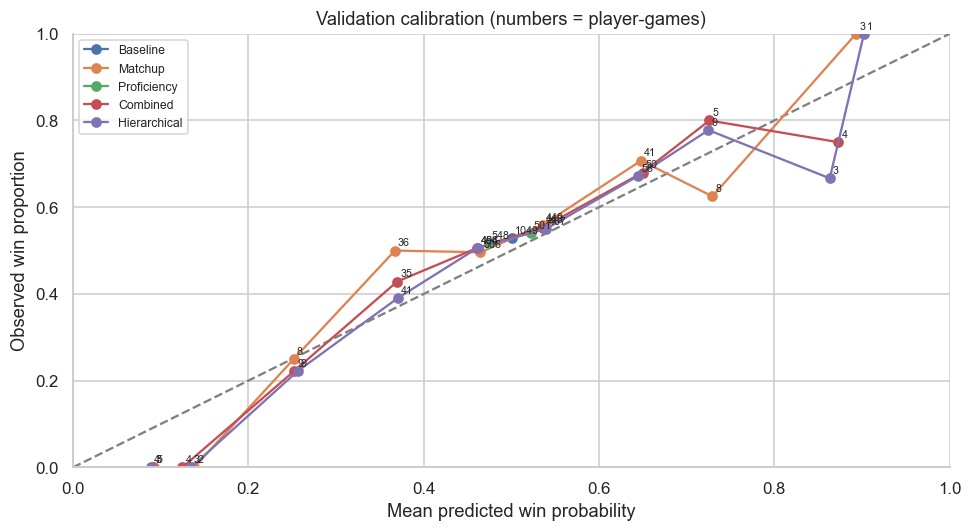

,bin,n,mean_prediction,observed,model
0,"(0.5, 0.6]",1049,0.5004,0.5281,Baseline
1,"(-0.001, 0.1]",5,0.0920,0.0000,Matchup
2,"(0.1, 0.2]",2,0.1383,0.0000,Matchup
3,"(0.2, 0.3]",8,0.2518,0.2500,Matchup
4,"(0.3, 0.4]",36,0.3672,0.5000,Matchup
5,"(0.4, 0.5]",506,0.4648,0.4960,Matchup
6,"(0.5, 0.6]",440,0.5358,0.5591,Matchup
7,"(0.6, 0.7]",41,0.6480,0.7073,Matchup
8,"(0.7, 0.8]",8,0.7294,0.6250,Matchup
9,"(0.8, 0.9]",3,0.8932,1.0000,Matchup


Max validation probability change across VB initializations: 5.6605377274365765e-08


Validation combined-minus-matchup log loss is **-0.00065**; hierarchical-minus-combined is **+0.00084**. Negative differences favor the added terms or hierarchy. All prespecified primary models remain in the final comparison regardless of these results.

In [4]:
gh_x,gh_w=hermgauss(40);gh_w=gh_w/np.sqrt(np.pi)
hyper_x,hyper_w=hermgauss(20);hyper_w=hyper_w/np.sqrt(np.pi)
def logistic_normal(mean,var):
    return (expit(np.asarray(mean)[:,None]+np.sqrt(2*np.maximum(var,0))[:,None]*gh_x)*gh_w).sum(axis=1)
def hierarchical_predict(f,result=hfit):
    X=np.column_stack([np.ones(len(f)),design_apply(d,f)])
    m=X@result.fe_mean;v=X**2@result.fe_sd**2
    codes=players.get_indexer(f.puuid);known=codes>=0
    out=np.empty(len(f))
    out[known]=logistic_normal(m[known]+result.vc_mean[codes[known]],v[known]+result.vc_sd[codes[known]]**2)
    if (~known).any():
        sigma2=np.exp(2*(result.vcp_mean[0]+np.sqrt(2)*result.vcp_sd[0]*hyper_x))
        out[~known]=sum(weight*logistic_normal(m[~known],v[~known]+s2) for s2,weight in zip(sigma2,hyper_w))
    return out
baseline=float(train.win.mean())
def primary_predict(f):
    out={'Baseline':np.full(len(f),baseline)}
    out.update({name:x['model'].predict_proba(design_apply(x['design'],f))[:,1] for name,x in ordinary.items()})
    out['Hierarchical']=hierarchical_predict(f)
    return out
def score_rows(f,predictions):
    rows=[]
    for name,p in predictions.items():
        assert len(p)==len(f) and np.isfinite(p).all()
        p=np.clip(p,1e-12,1-1e-12);y=f.win.to_numpy()
        losses=pd.DataFrame({'player':f.puuid.to_numpy(),'ll':-(y*np.log(p)+(1-y)*np.log(1-p)),'brier':(y-p)**2})
        equal=losses.groupby('player')[['ll','brier']].mean().mean()
        rows.append({'model':name,'n':len(f),'players':f.puuid.nunique(),'log_loss':log_loss(y,p),
            'brier':brier_score_loss(y,p),'auc':roc_auc_score(y,p),
            'equal_player_log_loss':equal['ll'],'equal_player_brier':equal['brier']})
    return pd.DataFrame(rows).set_index('model')
def calibrate(f,predictions,title):
    fig,ax=plt.subplots(figsize=(9,5));rows=[]
    ax.plot([0,1],[0,1],'--',color='gray')
    for name,p in predictions.items():
        temp=pd.DataFrame({'p':p,'y':f.win.to_numpy(),'bin':pd.cut(p,np.linspace(0,1,11),include_lowest=True)})
        g=temp.groupby('bin',observed=True).agg(n=('y','size'),mean_prediction=('p','mean'),observed=('y','mean'))
        ax.plot(g.mean_prediction,g.observed,'o-',label=name)
        for r in g.itertuples():ax.annotate(str(r.n),(r.mean_prediction,r.observed),fontsize=7,xytext=(2,3),textcoords='offset points')
        rows.append(g.assign(model=name).reset_index())
    ax.set(xlabel='Mean predicted win probability',ylabel='Observed win proportion',title=title,xlim=(0,1),ylim=(0,1))
    ax.legend(fontsize=8);done()
    return pd.concat(rows,ignore_index=True)
val_predictions=primary_predict(validation)
val_scores=score_rows(validation,val_predictions)
table(val_scores)
val_calibration=calibrate(validation,val_predictions,'Validation calibration (numbers = player-games)')
table(val_calibration)
stability=np.max(np.abs(hierarchical_predict(validation,hfit)-hierarchical_predict(validation,hcheck)))
print('Max validation probability change across VB initializations:',stability)
assert stability<1e-3
note(f'Validation combined-minus-matchup log loss is **{val_scores.loc["Combined","log_loss"]-val_scores.loc["Matchup","log_loss"]:+.5f}**; '
     f'hierarchical-minus-combined is **{val_scores.loc["Hierarchical","log_loss"]-val_scores.loc["Combined","log_loss"]:+.5f}**. '
     'Negative differences favor the added terms or hierarchy. All prespecified primary models remain in the final comparison regardless of these results.')

## Conditional coefficients and player variation

Odds ratios below describe changes in conditional modeled odds, holding other terms fixed. They are not feature importance, probabilities or causal effects. Ordinary L2 coefficients have no naive standard-error intervals. Hierarchical intervals are approximate marginal 95% variational intervals, not dependence-robust uncertainty; shared matches and omitted context can make them overconfident. Ordinary/hierarchical differences combine random effects with different regularization and fitting methods.

,model,term,comparison,log_odds_change,odds_ratio
0,Matchup,log_total,doubling (1 + prior total games),-0.0867,0.9169
1,Matchup,global_raw_matchup_winrate_probability,+10 pp raw Global rate,0.4453,1.5610
2,Matchup,lane_jungle,lane versus adc,0.0850,1.0887
3,Matchup,lane_mid,lane versus adc,-0.0932,0.9110
4,Matchup,lane_support,lane versus adc,-0.1308,0.8774
5,Matchup,lane_top,lane versus adc,0.0364,1.0370
6,Proficiency,log_total,doubling (1 + prior total games),-0.0889,0.9149
7,Proficiency,prior_champion_usage_share,+10 pp selected-champion usage,0.0136,1.0137
8,Proficiency,prior_champion_wr_beta11,+10 pp historical WR β,0.0436,1.0446
9,Proficiency,lane_jungle,lane versus adc,0.0921,1.0964


,term,comparison,log_odds_change,odds_ratio,approx_OR_low,approx_OR_high
0,log_total,doubling (1 + prior total games),-0.0485,0.9527,0.8037,1.1293
1,global_raw_matchup_winrate_probability,+10 pp raw Global rate,0.4532,1.5734,1.4328,1.7277
2,prior_champion_usage_share,+10 pp selected-champion usage,0.0198,1.0200,1.0027,1.0376
3,prior_champion_wr_beta11,+10 pp historical WR β,0.0317,1.0322,0.9785,1.0888
4,lane_jungle,lane versus adc,0.0742,1.0770,0.9432,1.2297
5,lane_mid,lane versus adc,-0.1231,0.8842,0.7881,0.9921
6,lane_support,lane versus adc,-0.1622,0.8503,0.7427,0.9734
7,lane_top,lane versus adc,0.0299,1.0303,0.9035,1.1749


Standardized-design intercepts: {'Matchup': 0.022526838826568467, 'Proficiency': 0.018032179596711943, 'Combined': 0.02219982488823744}
Hierarchical standardized-design intercept mean / SD: 0.038831121866660066 0.028342081238249228
Player log-odds SD posterior median: 0.17611544763970452 approx 95% interval: [0.15845649 0.19574238]


,training_games,mean,sd
count,177.0000,177.0000,177.0000
mean,28.7345,0.0000,0.1606
std,27.8599,0.0609,0.0117
min,1.0000,-0.1579,0.1142
25%,9.0000,-0.0331,0.1528
50%,19.0000,0.0013,0.1641
75%,42.0000,0.0330,0.1699
max,184.0000,0.2053,0.1750


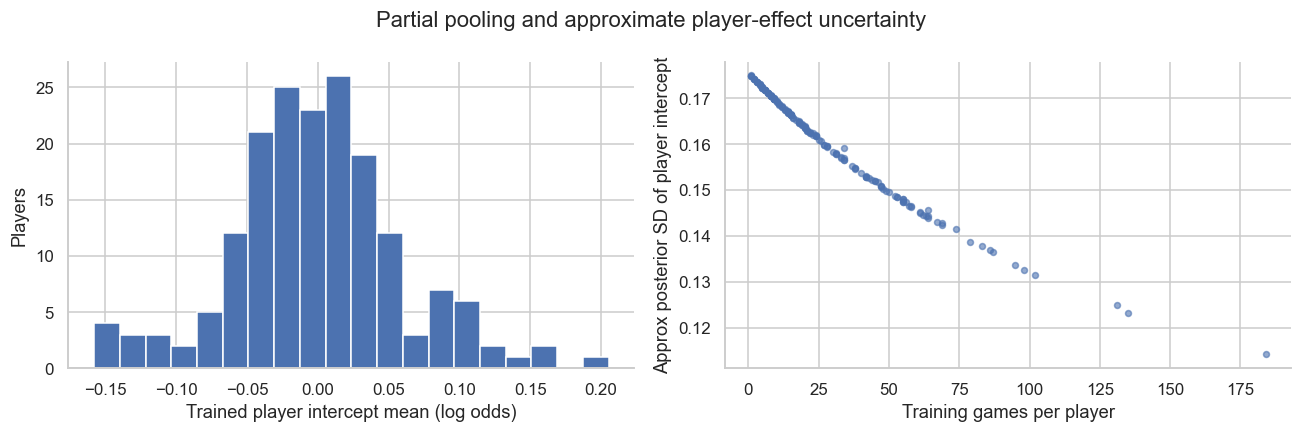

Player intercepts represent residual observed outcome propensity conditional on this small design, including omitted context and sampling. They are not pure skill scores. No individual rankings or independent-row significance claims are made.

In [5]:
units={'log_total':(np.log(2),'doubling (1 + prior total games)'),GLOBAL:(.1,'+10 pp raw Global rate'),
       USAGE:(.1,'+10 pp selected-champion usage'),WR:(.1,'+10 pp historical WR β')}
coef_rows=[]
for name,fit in ordinary.items():
    des=fit['design']
    for j,term in enumerate(des['names']):
        continuous_term=j<len(des['cols'])
        increment,unit=units.get(term,(1.,'lane versus '+str(des['encoder'].categories_[0][0])))
        factor=increment/des['scaler'].scale_[j] if continuous_term else 1.
        coef_rows.append({'model':name,'term':term,'comparison':unit,'log_odds_change':fit['model'].coef_[0,j]*factor,
                         'odds_ratio':np.exp(fit['model'].coef_[0,j]*factor)})
table(pd.DataFrame(coef_rows))
hrows=[]
for j,term in enumerate(d['names']):
    increment,unit=units.get(term,(1.,'lane versus '+str(d['encoder'].categories_[0][0])))
    factor=increment/d['scaler'].scale_[j] if j<len(d['cols']) else 1.
    mu=hfit.fe_mean[j+1]*factor;sd=hfit.fe_sd[j+1]*abs(factor)
    hrows.append({'term':term,'comparison':unit,'log_odds_change':mu,'odds_ratio':np.exp(mu),
                  'approx_OR_low':np.exp(mu-1.96*sd),'approx_OR_high':np.exp(mu+1.96*sd)})
table(pd.DataFrame(hrows))
print('Standardized-design intercepts:',{name:float(fit['model'].intercept_[0]) for name,fit in ordinary.items()})
print('Hierarchical standardized-design intercept mean / SD:',hfit.fe_mean[0],hfit.fe_sd[0])
sigma_median=np.exp(hfit.vcp_mean[0]);sigma_interval=np.exp(hfit.vcp_mean[0]+np.array([-1.96,1.96])*hfit.vcp_sd[0])
print('Player log-odds SD posterior median:',sigma_median,'approx 95% interval:',sigma_interval)
player_effects=pd.DataFrame({'training_games':train.groupby('puuid').size().reindex(players).to_numpy(),
    'mean':hfit.vc_mean,'sd':hfit.vc_sd},index=players)
table(player_effects[['training_games','mean','sd']].describe())
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(player_effects['mean'],bins=20);axes[0].set(xlabel='Trained player intercept mean (log odds)',ylabel='Players')
axes[1].scatter(player_effects.training_games,player_effects.sd,s=15,alpha=.6)
axes[1].set(xlabel='Training games per player',ylabel='Approx posterior SD of player intercept')
fig.suptitle('Partial pooling and approximate player-effect uncertainty');done()
note('Player intercepts represent residual observed outcome propensity conditional on this small design, including omitted context and sampling. '
     'They are not pure skill scores. No individual rankings or independent-row significance claims are made.')

## Focused validation sensitivities

The count sensitivity replaces usage with `log1p(prior_champion_games)` in ordinary combined logistic regression, keeping lane, log total, matchup, and WR β. It receives its own training-only scaler and the same fixed regularization.

The final EDA already reconstructs previous-50 and previous-100 usage from saved history. They are not persisted as columns, so the same recorded-game algorithm is reproduced here for training and validation targets only: queue 420, deduplicate by player/match, completion strictly before target kickoff, sort by start then match ID, require full windows. No outcomes are read from history. Compare expanding/50/100 ordinary combined models on identical complete-window training and validation targets, refitting all three on that training subset. This isolates window differences. These rolling diagnostics will remain validation-only; no window is selected for final test.

In [6]:
count_fit=ordinary_fit(train,['log_total',GLOBAL,'log_champion',WR])
count_val=count_fit['model'].predict_proba(design_apply(count_fit['design'],validation))[:,1]
count_scores=score_rows(validation,{'Combined expanding':val_predictions['Combined'],'Count replacement':count_val})
table(count_scores)
source=ROOT/metadata['input_longitudinal_snapshot']
history_cols=KEY+['timestamp','end_timestamp','champion_id','queue']
paths=[source/(name+'.parquet') for name in ['historical_matches','target_matches']]
if not all(p.is_file() for p in paths):
    raise FileNotFoundError('Saved rolling histories used by final EDA are missing: '+str(paths))
pool=pd.concat([pd.read_parquet(p,columns=history_cols) for p in paths],ignore_index=True).drop_duplicates(KEY)
pool=pool.loc[pool.queue.eq(420)&pool.timestamp.lt(cut2)&pool.end_timestamp.lt(cut2)].sort_values(['puuid','timestamp','match_id'],kind='stable')
tv=pd.concat([train,validation],ignore_index=True)
rolling=[]
for player,targets in tv.groupby('puuid',sort=False):
    h=pool.loc[pool.puuid.eq(player)]
    for r in targets[KEY+['timestamp','champion_id']].itertuples(index=False):
        eligible=h.loc[h.end_timestamp.lt(r.timestamp)&h.timestamp.lt(r.timestamp)]
        champions=eligible.champion_id.to_numpy()
        row={'puuid':player,'match_id':r.match_id,'recorded_n':len(champions)}
        for w in [50,100]:row[f'usage{w}']=np.mean(champions[-w:]==r.champion_id) if len(champions)>=w else np.nan
        rolling.append(row)
tv=tv.merge(pd.DataFrame(rolling),on=KEY,validate='one_to_one')
assert tv.recorded_n.eq(tv.prior_total_games).all()
complete=tv[['usage50','usage100',USAGE]].notna().all(axis=1)
rt=tv.loc[complete&tv.partition.eq('train')].copy()
rv=tv.loc[complete&tv.partition.eq('validation')].copy()
display(pd.DataFrame([{'partition':label,'before':len(before),'retained':len(after),
    'players_retained':after.puuid.nunique(),'short_history_excluded':len(before)-len(after)}
    for label,before,after in [('train',train,rt),('validation',validation,rv)]]))
rolling_fits={};rolling_predictions={}
for label,col in [('Expanding matched',USAGE),('Previous 50','usage50'),('Previous 100','usage100')]:
    fit=ordinary_fit(rt,['log_total',GLOBAL,col,WR]);rolling_fits[label]=fit
    rolling_predictions[label]=fit['model'].predict_proba(design_apply(fit['design'],rv))[:,1]
rolling_scores=score_rows(rv,rolling_predictions)
table(rolling_scores)
note('Rolling estimates are descriptive model-specification sensitivities on their own matched population. '
     'Their scores should be compared within this table, not directly with primary scores on different rows. '
     'No count, window or benchmark is chosen for supporting a preferred hypothesis.')

,n,players,log_loss,brier,auc,equal_player_log_loss,equal_player_brier
model,,,,,,,
Combined expanding,1049,128,0.6834,0.2456,0.5612,0.6874,0.2476
Count replacement,1049,128,0.6851,0.2465,0.5561,0.6885,0.2481


,partition,before,retained,players_retained,short_history_excluded
0,train,5086,4940,173,146
1,validation,1049,1039,126,10


,n,players,log_loss,brier,auc,equal_player_log_loss,equal_player_brier
model,,,,,,,
Expanding matched,1039,126,0.6835,0.2457,0.5594,0.6882,0.2480
Previous 50,1039,126,0.6837,0.2458,0.5576,0.6880,0.2479
Previous 100,1039,126,0.6837,0.2458,0.5577,0.6880,0.2479


Rolling estimates are descriptive model-specification sensitivities on their own matched population. Their scores should be compared within this table, not directly with primary scores on different rows. No count, window or benchmark is chosen for supporting a preferred hypothesis.

## Freeze record — before accessing test outcomes

The final comparison contains the baseline, all four primary models, and the ordinary count-replacement sensitivity. Rolling fits remain validation-only by the prespecified scope. No model is refitted on validation outcomes. The next cell freezes test probabilities using training-fitted parameters; the subsequent cell opens test responses and scores this comparison exactly once. Re-executing this notebook reproduces the fixed plan rather than initiating a test-driven search.

In [7]:
FINAL_MODELS=('Baseline','Matchup','Proficiency','Combined','Hierarchical','Count replacement')
test_predictions=primary_predict(test_features)
test_predictions['Count replacement']=count_fit['model'].predict_proba(design_apply(count_fit['design'],test_features))[:,1]
assert tuple(test_predictions)==FINAL_MODELS
for p in test_predictions.values():p.setflags(write=False)
freeze={'models':list(FINAL_MODELS),'ordinary_C':1.,'training_rows':len(train),
        'training_only_parameters':True,'refit_on_validation':False,
        'rolling_final_test':False,'validation_start':str(VALID_START),'test_start':str(TEST_START)}
print(json.dumps(freeze,indent=2))
assert 'win' not in test_features

{
  "models": [
    "Baseline",
    "Matchup",
    "Proficiency",
    "Combined",
    "Hierarchical",
    "Count replacement"
  ],
  "ordinary_C": 1.0,
  "training_rows": 5086,
  "training_only_parameters": true,
  "refit_on_validation": false,
  "rolling_final_test": false,
  "validation_start": "2026-10-02 22:25:06.238000+00:00",
  "test_start": "2026-10-05 01:32:18.312000+00:00"
}


,n,players,log_loss,brier,auc,equal_player_log_loss,equal_player_brier
model,,,,,,,
Baseline,1065,127,0.6931,0.2500,0.5000,0.6931,0.2500
Matchup,1065,127,0.6804,0.2443,0.5703,0.6869,0.2474
Proficiency,1065,127,0.6925,0.2497,0.5238,0.6948,0.2508
Combined,1065,127,0.6801,0.2441,0.5713,0.6879,0.2479
Hierarchical,1065,127,0.6806,0.2444,0.5639,0.6878,0.2479
Count replacement,1065,127,0.6804,0.2443,0.5722,0.6901,0.2490


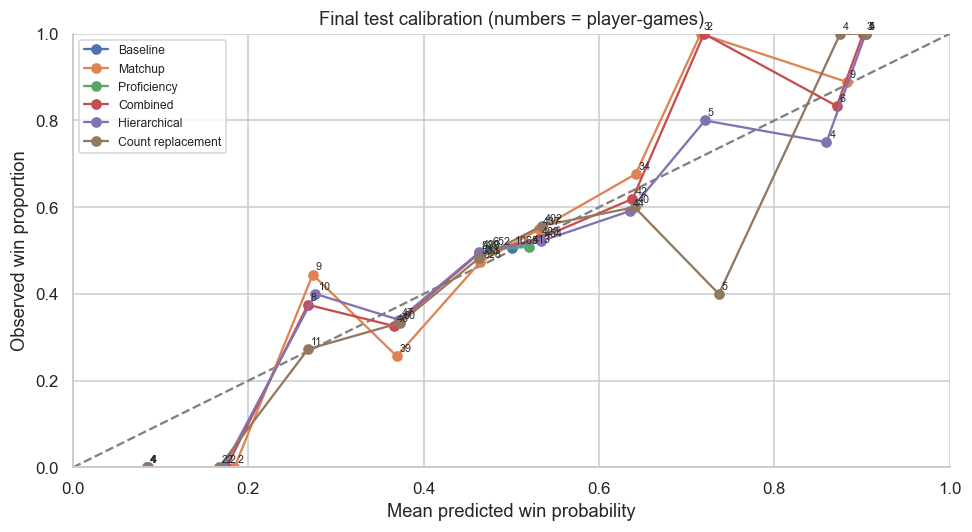

,bin,n,mean_prediction,observed,model
0,"(0.5, 0.6]",1065,0.5004,0.5052,Baseline
1,"(-0.001, 0.1]",4,0.0852,0.0000,Matchup
2,"(0.1, 0.2]",2,0.1842,0.0000,Matchup
3,"(0.2, 0.3]",9,0.2734,0.4444,Matchup
4,"(0.3, 0.4]",39,0.3693,0.2564,Matchup
5,"(0.4, 0.5]",528,0.4645,0.4735,Matchup
6,"(0.5, 0.6]",437,0.5319,0.5492,Matchup
7,"(0.6, 0.7]",34,0.6418,0.6765,Matchup
8,"(0.7, 0.8]",3,0.7159,1.0000,Matchup
9,"(0.8, 0.9]",9,0.8827,0.8889,Matchup


,partition,known_rows,unseen_rows,unseen_players
0,validation,1021,28,5
1,test,1057,8,4


In [8]:
# First and only test-outcome evaluation stage. Do not revise the specification afterward.
test_labels=pd.read_parquet(DATA/'observed_global_analysis.parquet',columns=KEY+['win'],filters=[('timestamp','>=',int(cut2))])
test=test_features.merge(test_labels,on=KEY,validate='one_to_one',how='left')
assert test.win.notna().all() and test[KEY].equals(test_features[KEY].reset_index(drop=True))
test_scores=score_rows(test,test_predictions)
table(test_scores)
test_calibration=calibrate(test,test_predictions,'Final test calibration (numbers = player-games)')
table(test_calibration)
# Known/unseen breakdown describes support, not a new model selection criterion.
known_test=test.puuid.isin(players)
display(pd.DataFrame([{'partition':label,'known_rows':int(f.puuid.isin(players).sum()),
    'unseen_rows':int((~f.puuid.isin(players)).sum()),'unseen_players':f.loc[~f.puuid.isin(players),'puuid'].nunique()}
    for label,f in [('validation',validation),('test',test)]]))

## What the fitted comparisons establish

Lower log loss and Brier are better; higher AUC is better. Small changes are not evidence of a reliable improvement without dependence-aware uncertainty and replication. No row-level significance tests are supplied. The following interpretation is generated from the executed scores, including contrary evidence.

In [9]:
for split,scores in [('Validation',val_scores),('Final test',test_scores)]:
    delta_prof=scores.loc['Combined','log_loss']-scores.loc['Matchup','log_loss']
    delta_player=scores.loc['Hierarchical','log_loss']-scores.loc['Combined','log_loss']
    note(f'**{split}:** adding proficiency to matchup changes log loss by **{delta_prof:+.5f}** '
         f'and Brier by **{scores.loc["Combined","brier"]-scores.loc["Matchup","brier"]:+.5f}**; '
         f'player pooling changes log loss by **{delta_player:+.5f}** '
         f'and Brier by **{scores.loc["Hierarchical","brier"]-scores.loc["Combined","brier"]:+.5f}**. '
         f'Combined/hierarchical AUCs are **{scores.loc["Combined","auc"]:.3f}/{scores.loc["Hierarchical","auc"]:.3f}**. '
         'Negative loss changes favor the more elaborate specification; equal-player results above show the alternative weighting.')
prof_validation=val_scores.loc['Combined','log_loss']<val_scores.loc['Matchup','log_loss']
prof_test=test_scores.loc['Combined','log_loss']<test_scores.loc['Matchup','log_loss']
player_validation=val_scores.loc['Hierarchical','log_loss']<val_scores.loc['Combined','log_loss']
player_test=test_scores.loc['Hierarchical','log_loss']<test_scores.loc['Combined','log_loss']
note(f'**Predictive conclusion:** proficiency improves game-weighted log loss on validation: **{prof_validation}**; '
     f'on final test: **{prof_test}**. Player effects improve it on validation: **{player_validation}**; '
     f'on final test: **{player_test}**. These are finite-sample comparisons, not significance claims. '
     'Read the Brier, AUC, calibration and equal-player summaries alongside log loss; a conditional coefficient alone does not establish predictive improvement.')
combined=ordinary['Combined'];des=combined['design']
for term in [GLOBAL,USAGE,WR]:
    j=des['cols'].index(term)
    odds=np.exp(combined['model'].coef_[0,j]*.1/des['scaler'].scale_[j])
    note(f'**Conditional ordinary combined relationship:** +10 percentage points in `{term}` corresponds to '
         f'an odds ratio of **{odds:.3f}**, holding the remaining terms fixed. '
         'This is an associational conditional relationship, not a causal practice or switching effect.')
note(f'**Player variation:** estimated population player log-odds SD has median **{sigma_median:.3f}** '
     f'and approximate variational 95% interval **[{sigma_interval[0]:.3f}, {sigma_interval[1]:.3f}]**. '
     'Pooling shrinks sparse player estimates toward the population; posterior uncertainty remains approximate and omits cross-parameter correlations. '
     'Successful optimizer and initialization checks support numerical stability, not the accuracy of uncertainty intervals.')
note('**Remaining uncertainty and next steps:** the paired losses have not received dependence-aware intervals; player repetition and shared matches '
     'preclude naive row tests. Hierarchical likelihoods still assume conditional row independence and omit shared-match/context effects. '
     'History is capped initially and season bounded; historical WR blends skill with opponents, teammates, selection and chance. '
     'Lane/opponent are inferred after play and need a deployable pregame mapping. External patch-wide raw Global rates are retrospective, '
     'not guaranteed to have existed at kickoff. The chronology mostly measures later games of known players; new-player generalization needs a separate design. '
     'Proficiency-versus-matchup tradeoffs warrant further investigation through prespecified replication and richer dependence handling, '
     'with priority guided by the predictive comparisons above, not a desired OTP story. No exact OTP threshold, causal benefit, '
     'or counterfactual outcome for an unplayed alternative has been established.')
print('Completed: frozen primary/test evaluation and focused validation sensitivities; source datasets and EDA unchanged.')

**Validation:** adding proficiency to matchup changes log loss by **-0.00065** and Brier by **-0.00031**; player pooling changes log loss by **+0.00084** and Brier by **+0.00042**. Combined/hierarchical AUCs are **0.561/0.554**. Negative loss changes favor the more elaborate specification; equal-player results above show the alternative weighting.

**Final test:** adding proficiency to matchup changes log loss by **-0.00027** and Brier by **-0.00011**; player pooling changes log loss by **+0.00046** and Brier by **+0.00024**. Combined/hierarchical AUCs are **0.571/0.564**. Negative loss changes favor the more elaborate specification; equal-player results above show the alternative weighting.

**Predictive conclusion:** proficiency improves game-weighted log loss on validation: **True**; on final test: **True**. Player effects improve it on validation: **False**; on final test: **False**. These are finite-sample comparisons, not significance claims. Read the Brier, AUC, calibration and equal-player summaries alongside log loss; a conditional coefficient alone does not establish predictive improvement.

**Conditional ordinary combined relationship:** +10 percentage points in `global_raw_matchup_winrate_probability` corresponds to an odds ratio of **1.559**, holding the remaining terms fixed. This is an associational conditional relationship, not a causal practice or switching effect.

**Conditional ordinary combined relationship:** +10 percentage points in `prior_champion_usage_share` corresponds to an odds ratio of **1.014**, holding the remaining terms fixed. This is an associational conditional relationship, not a causal practice or switching effect.

**Conditional ordinary combined relationship:** +10 percentage points in `prior_champion_wr_beta11` corresponds to an odds ratio of **1.036**, holding the remaining terms fixed. This is an associational conditional relationship, not a causal practice or switching effect.

**Player variation:** estimated population player log-odds SD has median **0.176** and approximate variational 95% interval **[0.158, 0.196]**. Pooling shrinks sparse player estimates toward the population; posterior uncertainty remains approximate and omits cross-parameter correlations. Successful optimizer and initialization checks support numerical stability, not the accuracy of uncertainty intervals.

**Remaining uncertainty and next steps:** the paired losses have not received dependence-aware intervals; player repetition and shared matches preclude naive row tests. Hierarchical likelihoods still assume conditional row independence and omit shared-match/context effects. History is capped initially and season bounded; historical WR blends skill with opponents, teammates, selection and chance. Lane/opponent are inferred after play and need a deployable pregame mapping. External patch-wide raw Global rates are retrospective, not guaranteed to have existed at kickoff. The chronology mostly measures later games of known players; new-player generalization needs a separate design. Proficiency-versus-matchup tradeoffs warrant further investigation through prespecified replication and richer dependence handling, with priority guided by the predictive comparisons above, not a desired OTP story. No exact OTP threshold, causal benefit, or counterfactual outcome for an unplayed alternative has been established.

Completed: frozen primary/test evaluation and focused validation sensitivities; source datasets and EDA unchanged.


### Reading the results together

The primary fits use **5,086 training games from 177 players**. Validation has **1,049 games**, and the frozen final test has **1,065 games**. Only 28 validation rows (5 players) and 8 test rows (4 players) come from players absent in training, so unseen-player behavior remains weakly assessed.

The raw matchup term has a substantially larger conditional odds change than either proficiency term at their stated +10-percentage-point units. In the ordinary combined model, these odds ratios are **1.559 for matchup**, **1.014 for usage**, and **1.036 for historical WR β**. The hierarchical model likewise retains a positive matchup relationship, with small proficiency relationships. These different constructs and increments do not provide a causal ranking of player skill factors.

**Proficiency's predictive increment is small and weighting-sensitive.** Test game-weighted log loss is approximately **0.6804 for Matchup**, **0.6801 for Combined**, and **0.6806 for Hierarchical**. But equal-player test log loss is **0.6869 for Matchup versus 0.6879 for Combined**, and equal-player Brier also favors Matchup. Adding proficiency therefore offers a small observed improvement for the game-weighted target, not a robust improvement across both weighting schemes. The hierarchical model does not improve game-weighted validation or test loss; its small equal-player test advantage over Combined does not establish a general benefit from player effects.

**Sensitivity results do not reveal a preferred recent window.** On validation, the count replacement has log loss **0.6851**, versus **0.6834** for expanding usage on the same 1,049 rows. The complete-window comparison retains **4,940 training and 1,039 validation rows**. On those matched validation rows, expanding/previous-50/previous-100 log losses are **0.6835 / 0.6837 / 0.6837**. Equal-player losses differ only slightly and slightly favor the recent windows. These small, metric-sensitive contrasts justify retaining the expanding primary specification without asserting that a window is intrinsically best.

Calibration tables show that most predictions fall between 0.4 and 0.6. Extreme probability bins contain very few games, so jagged calibration tails are not reliable evidence for a calibration fix. No calibration adjustment was fitted after viewing test data.

The numerical VB checks passed: both initializations converged to the same objective and differed by less than **0.000001** in validation win probabilities. The main VB fit took about **3 seconds** in this environment; the repeat took about **2 seconds**. This establishes numerical stability of this approximation, not exact posterior or dependence-robust uncertainty. Overall, the evidence supports modest, carefully qualified further investigation of proficiency–matchup tradeoffs, with stronger dependence-aware validation and prospective benchmarks before individual recommendations.
